Assignment 2. Design and implement a Multilayer Perceptron (MLP) for classification of the Iris or Wine dataset, and evaluate its performance using accuracy and a confusion matrix.

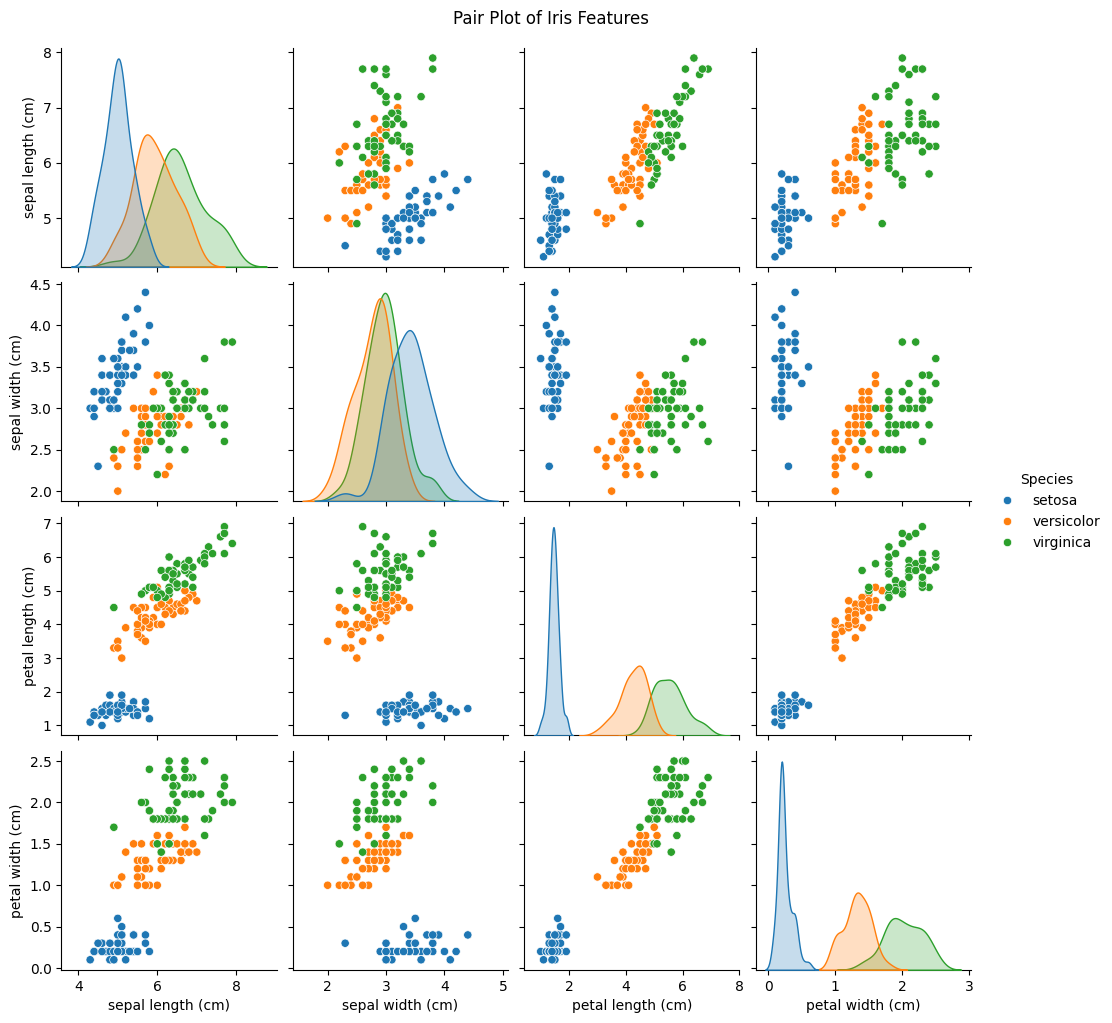

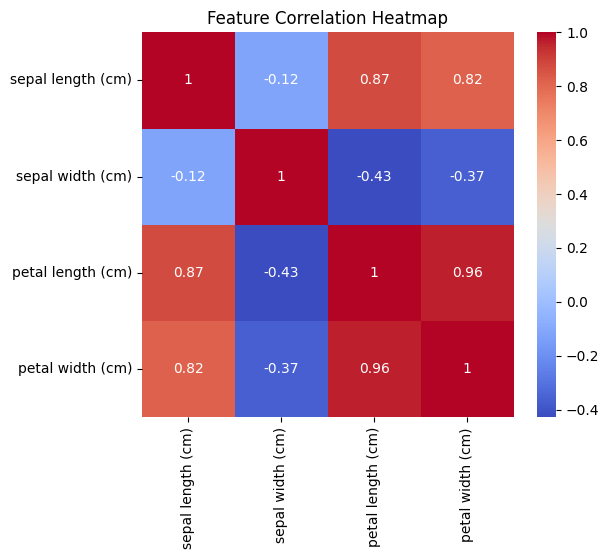

Accuracy: 0.9666666666666667

Confusion Matrix:
[[10  0  0]
 [ 0  8  1]
 [ 0  0 11]]

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.89      0.94         9
   virginica       0.92      1.00      0.96        11

    accuracy                           0.97        30
   macro avg       0.97      0.96      0.97        30
weighted avg       0.97      0.97      0.97        30



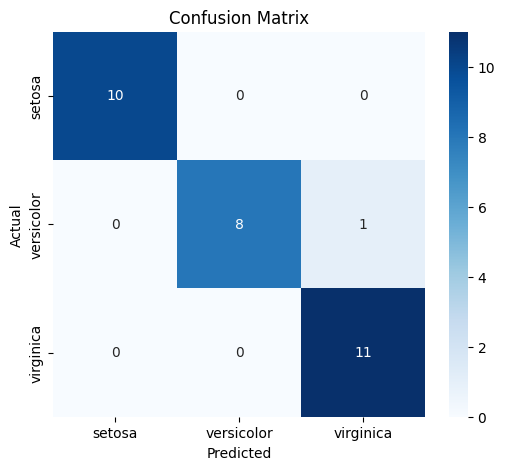

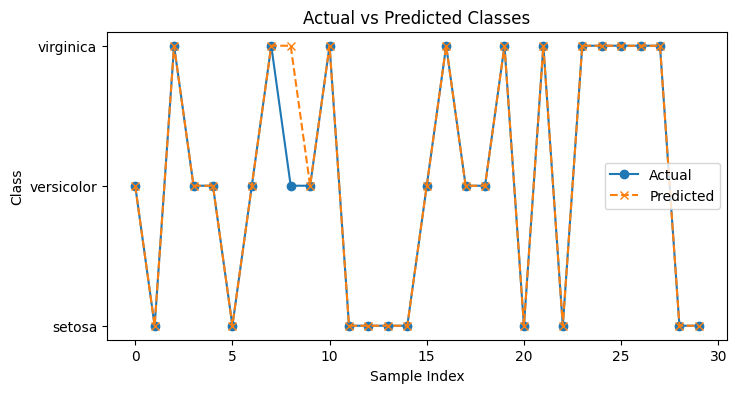

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Load Dataset
iris = load_iris()
X, y = iris.data, iris.target

# DataFrame for Visualization
df = pd.DataFrame(X, columns=iris.feature_names)
df["Species"] = pd.Categorical.from_codes(y, iris.target_names)

# Visualization 1: Pair Plot
sns.pairplot(df, hue="Species")
plt.suptitle("Pair Plot of Iris Features", y=1.02)
plt.show()

# Visualization 2: Correlation Heatmap
plt.figure(figsize=(6,5))
sns.heatmap(df.iloc[:, :-1].corr(), annot=True, cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.show()

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Feature Scaling
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# MLP Model
mlp = MLPClassifier(
    hidden_layer_sizes=(10, 10),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

# Train Model
mlp.fit(X_train, y_train)

# Prediction
y_pred = mlp.predict(X_test)

# Evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=iris.target_names
))

# Visualization 3: Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# Visualization 4: Actual vs Predicted
plt.figure(figsize=(8,4))

plt.plot(y_test, 'o-', label='Actual')
plt.plot(y_pred, 'x--', label='Predicted')

plt.title("Actual vs Predicted Classes")
plt.xlabel("Sample Index")
plt.ylabel("Class")
plt.yticks([0, 1, 2], iris.target_names)
plt.legend()

plt.show()